In [1]:
import warnings
warnings.filterwarnings('ignore')

import os 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from enigmatoolbox.plotting import plot_cortical, plot_subcortical
from enigmatoolbox.utils.parcellation import parcel_to_surface
import nilearn.plotting

import sys
sys.path.append('..')

from helper.func import general_linear_model

In [ ]:
project_dir = os.path.abspath(os.path.join(os.getcwd(), '..', '..'))
results_dir = os.path.join(project_dir, '...')

In [ ]:
## demographics
demo = pd.read_csv(os.path.join(results_dir, '...', 'demo.csv'))
demo['Dx'] = pd.to_numeric(demo['Dx'], errors='coerce')

## cortical thickness
ctx_tle = pd.read_csv(os.path.join(results_dir, '...', 'ctx_tle_durill.csv'), index_col=0)
ctx_ige = pd.read_csv(os.path.join(results_dir, '...', 'ctx_ige_durill.csv'), index_col=0)

## subcortical volume
sv_tle = pd.read_csv(os.path.join(results_dir, '...', 'sv_tle_durill.csv'), index_col=0)
sv_ige = pd.read_csv(os.path.join(results_dir, '...', 'sv_ige_durill.csv'), index_col=0)


In [4]:
from matplotlib.colors import LinearSegmentedColormap
import matplotlib as mpl

my_rdbu = LinearSegmentedColormap.from_list(
    "my_rdbu", ["#174fa0", "#2f89c2", "#f7f7f7", "#df5948", "#ad0c28"], N=256)

try:
    mpl.colormaps.register(my_rdbu)
except ValueError:
    pass

## Effects of age in males

In [5]:
biomarker_datasets = {
    'ctx': {'tle': ctx_tle, 'ige': ctx_ige},
    'sv': {'tle': sv_tle, 'ige': sv_ige}
}

male_diagnosis = {}

for epi in ['tle', 'ige']:
    male_diagnosis[epi] = {}
    for biomarker in ['ctx', 'sv']:
        male_diagnosis[epi][biomarker] = {}

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        glm = general_linear_model(demo, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        male_diagnosis[epi][biomarker] = glm.clinical_correlate_across_sexes(
            df_name=df_name, durill_col="durill", ao_col="ao", age_col="Age",
            sex_col="Sex", icv_col="ICV", gender="male", correlate_variable="age")

In [6]:
## Reorganize results

epi_types = ['tle', 'ige']
biomarkers = ['ctx', 'sv']

metric_map = {
    't': 't_values', 'q': 'q_values', 
    'beta': 'beta', 'ci_lower': 'ci_lower', 'ci_upper': 'ci_upper'
}

male_metrics = {}

for biomarker in biomarkers:
    for metric_name, result_key in metric_map.items():

        stacked_values = []

        for epi in epi_types:
            values = male_diagnosis[epi][biomarker][result_key]
            values = np.asarray(values).flatten()

            stacked_values.append(values)

        male_metrics[f'{metric_name}_{biomarker}'] = np.vstack(stacked_values)

In [ ]:
## Save 

metrics_to_save = ['t', 'q', 'beta', 'ci_lower', 'ci_upper']
biomarkers = ['ctx', 'sv']
epi_types = ['tle', 'ige']

epi_index = {epi: i for i, epi in enumerate(epi_types)}
biomarker_index_map = {'ctx': ctx_tle.columns, 'sv': sv_tle.columns}

output_base = os.path.join(results_dir, '...', 'males')
os.makedirs(output_base, exist_ok=True)

for epi in epi_types:

    epi_dir = os.path.join(output_base, epi.upper())
    os.makedirs(epi_dir, exist_ok=True)

    epi_idx = epi_index[epi]

    for biomarker in biomarkers:
        index_cols = biomarker_index_map[biomarker]

        for metric in metrics_to_save:
            key = f'{metric}_{biomarker}'

            if key not in male_metrics:
                continue

            values = male_metrics[key][epi_idx, :]

            df = pd.DataFrame(values, index=index_cols, columns=[f'{metric}_value'])
            df['analysis'] = 'age effect'
            df['predictor'] = 'age'
            df['sex'] = 'male'
            df['diagnosis'] = epi.upper()
            df['metric'] = metric
            df['biomarker'] = biomarker

            out_name = f'{metric}_{biomarker}.csv'
            df.to_csv(os.path.join(epi_dir, out_name), index=True)

#### Cortical thickness in TLE

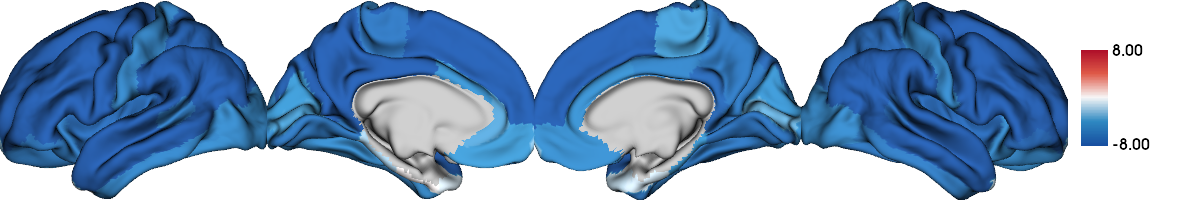

In [31]:
# plot t values in TLE
# label_text = ['TLE', 'IGE']

t_ctx_surf = parcel_to_surface(male_metrics['t_ctx'][0], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=True, color_range=(-8, 8))

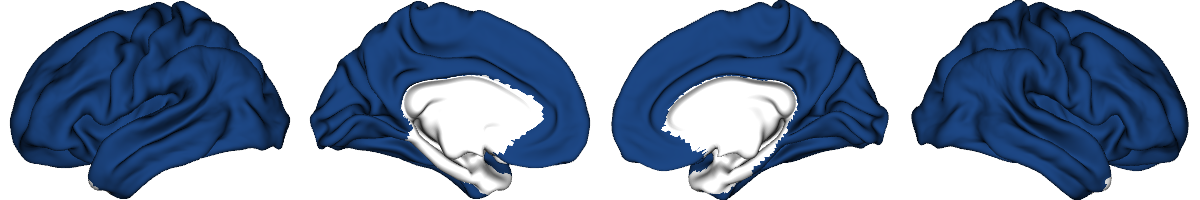

In [16]:
# plot p-sig regions

p_ctx_surf = parcel_to_surface(male_metrics['q_ctx'][0], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [17]:
## Check which areas are significant
q_ctx_tle = pd.Series(male_metrics['q_ctx'][0], index=ctx_tle.columns, name='pFDR')
q_ctx_tle[q_ctx_tle < 0.05].index

Index(['L_bankssts', 'L_caudalanteriorcingulate', 'L_caudalmiddlefrontal',
       'L_cuneus', 'L_fusiform', 'L_inferiorparietal', 'L_inferiortemporal',
       'L_isthmuscingulate', 'L_lateraloccipital', 'L_lateralorbitofrontal',
       'L_lingual', 'L_medialorbitofrontal', 'L_middletemporal',
       'L_paracentral', 'L_parsopercularis', 'L_parsorbitalis',
       'L_parstriangularis', 'L_pericalcarine', 'L_postcentral',
       'L_posteriorcingulate', 'L_precentral', 'L_precuneus',
       'L_rostralanteriorcingulate', 'L_rostralmiddlefrontal',
       'L_superiorfrontal', 'L_superiorparietal', 'L_superiortemporal',
       'L_supramarginal', 'L_frontalpole', 'L_transversetemporal', 'L_insula',
       'R_bankssts', 'R_caudalanteriorcingulate', 'R_caudalmiddlefrontal',
       'R_cuneus', 'R_fusiform', 'R_inferiorparietal', 'R_inferiortemporal',
       'R_isthmuscingulate', 'R_lateraloccipital', 'R_lateralorbitofrontal',
       'R_lingual', 'R_medialorbitofrontal', 'R_middletemporal',
       

In [18]:
len(q_ctx_tle[q_ctx_tle < 0.05])

63

In [34]:
# get the cohen's d values range for TLE in males
male_metrics['t_ctx'][0].min(), male_metrics['t_ctx'][0].max()

(-11.078682905940683, 0.14665371510426334)

In [35]:
# get the strongest effects (t values) for p significant regions for TLE in males
t_ctx_tle = pd.Series(male_metrics['t_ctx'][0], index=ctx_tle.columns, name="Cohen's_d")

tle_ctx = pd.DataFrame({
    "t": t_ctx_tle,
    "q-value": q_ctx_tle
})

tle_sig_ctx = tle_ctx[tle_ctx["q-value"] < 0.05].sort_values(by="t", ascending=True)
tle_sig_ctx.head(20)

,t,q-value
L_parsopercularis,-11.078683,1.405744e-23
L_caudalmiddlefrontal,-10.850928,3.747402e-23
R_superiorfrontal,-10.840725,3.747402e-23
L_superiorfrontal,-10.485243,5.978149e-22
R_parsopercularis,-10.363176,1.347602e-21
L_supramarginal,-10.192638,4.702061e-21
L_posteriorcingulate,-10.174585,4.702061e-21
L_middletemporal,-10.133751,5.786727e-21
L_parstriangularis,-10.096454,7.018886e-21
R_supramarginal,-9.714643,1.460516e-19


IGE

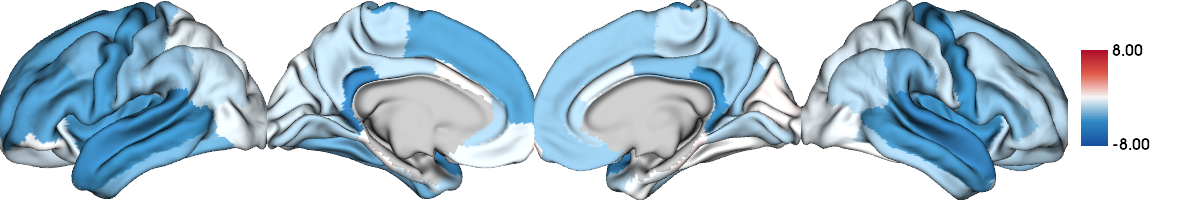

In [36]:
# plot t values in IGE
# label_text = ['TLE', 'IGE']

t_ctx_surf = parcel_to_surface(male_metrics['t_ctx'][1], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=True, color_range=(-8, 8))

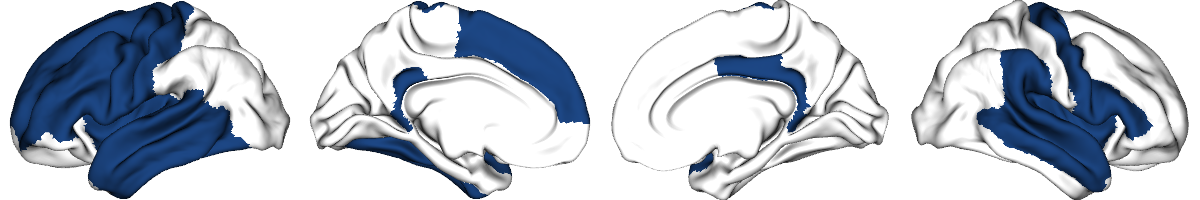

In [39]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(male_metrics['q_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [40]:
## Check which areas are significant
q_ctx_ige = pd.Series(male_metrics['q_ctx'][1], index=ctx_ige.columns, name='pFDR')
q_ctx_ige[q_ctx_ige < 0.05].index

Index(['L_bankssts', 'L_caudalmiddlefrontal', 'L_fusiform',
       'L_inferiortemporal', 'L_isthmuscingulate', 'L_middletemporal',
       'L_parsopercularis', 'L_parstriangularis', 'L_postcentral',
       'L_precentral', 'L_rostralmiddlefrontal', 'L_superiorfrontal',
       'L_superiortemporal', 'L_transversetemporal', 'L_insula', 'R_bankssts',
       'R_isthmuscingulate', 'R_middletemporal', 'R_parsopercularis',
       'R_parstriangularis', 'R_posteriorcingulate', 'R_precentral',
       'R_superiortemporal', 'R_supramarginal', 'R_transversetemporal',
       'R_insula'],
      dtype='object')

In [41]:
len(q_ctx_ige[q_ctx_ige < 0.05])

26

In [42]:
male_metrics['t_ctx'][1].min(), male_metrics['t_ctx'][1].max()

(-5.036573419022286, 0.6428494176452961)

In [45]:
t_ctx_ige = pd.Series(male_metrics['t_ctx'][1], index=ctx_ige.columns, name='pFDR')

ige_ctx = pd.DataFrame({
    "t": t_ctx_ige,
    "q-value": q_ctx_ige
})

ige_sig_ctx = ige_ctx[ige_ctx["q-value"] < 0.05].sort_values(by="t", ascending=True)
ige_sig_ctx.head(10)

,t,q-value
R_superiortemporal,-5.036573,0.000220
L_isthmuscingulate,-4.988180,0.000220
L_superiortemporal,-4.459688,0.000928
R_isthmuscingulate,-4.178579,0.001779
L_bankssts,-4.051579,0.001779
L_middletemporal,-4.042902,0.001779
R_precentral,-4.012578,0.001779
R_insula,-3.960784,0.001843
L_transversetemporal,-3.865010,0.002233
L_insula,-3.796962,0.002350


Subcortical volumes in TLE

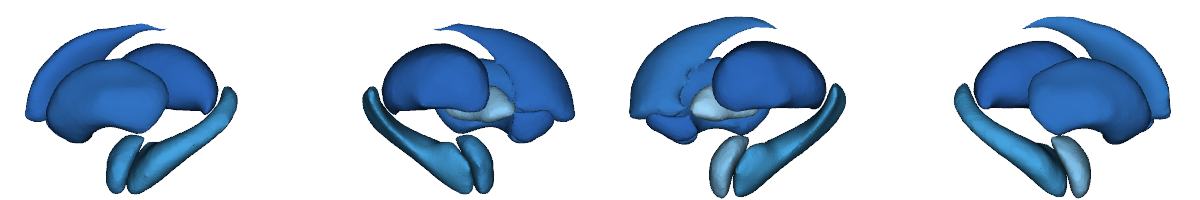

In [44]:
# plot t values in TLE
# label_text = ['TLE', 'IGE']

plot_subcortical(male_metrics['t_sv'][0], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                             label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-8, 8))

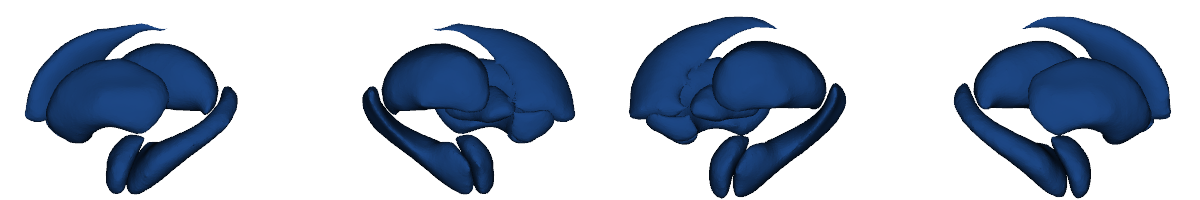

In [46]:
# plot p-sig areas

sig_mask = np.where(male_metrics['q_sv'][0] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [47]:
q_sv_tle = pd.Series(male_metrics['q_sv'][0], index=sv_tle.columns, name='pFDR')
q_sv_tle[q_sv_tle < 0.05].index

Index(['Laccumb', 'Lamyg', 'Lcaud', 'Lhippo', 'Lpal', 'Lput', 'Lthal',
       'Raccumb', 'Ramyg', 'Rcaud', 'Rhippo', 'Rpal', 'Rput', 'Rthal'],
      dtype='object')

In [48]:
male_metrics['t_sv'][0].min(), male_metrics['t_sv'][0].max()

(-9.304627202249884, -2.2932575368030976)

In [49]:
t_sv_tle = pd.Series(male_metrics['t_sv'][0], index=sv_tle.columns, name="t")

tle_sv = pd.DataFrame({
    "t": t_sv_tle,
    "q-value": q_sv_tle
})

tle_sig_sv = tle_sv[tle_sv["q-value"] < 0.05].sort_values(by="t", ascending=True)
tle_sig_sv.head()

,t,q-value
Lthal,-9.304627,8.101310e-18
Laccumb,-9.084331,2.277045e-17
Rthal,-8.175764,1.389912e-14
Raccumb,-7.931802,5.964773e-14
Lcaud,-7.701182,2.395569e-13


IGE

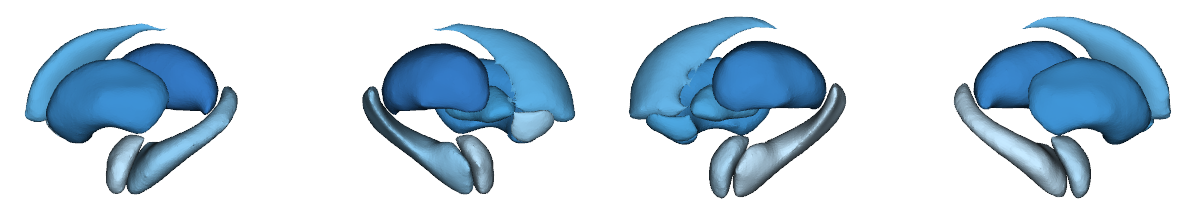

In [50]:
# plot t values in IGE
# label_text = ['TLE', 'IGE']

plot_subcortical(male_metrics['t_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                             label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-8, 8))

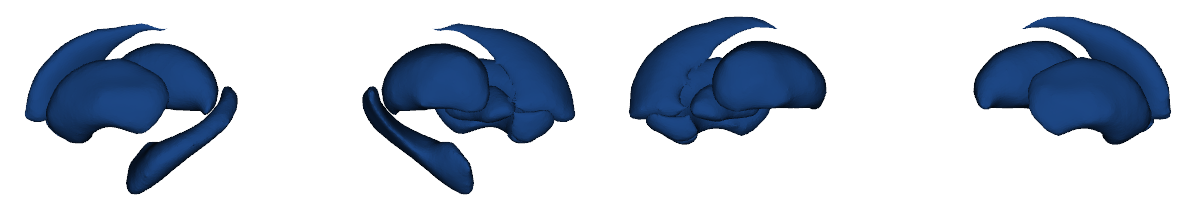

In [51]:
# plot p-sig areas

sig_mask = np.where(male_metrics['q_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [52]:
## Check which subcortical areas are significant in IGE
q_sv_ige = pd.Series(male_metrics['q_sv'][1], index=sv_ige.columns, name='pFDR')
q_sv_ige[q_sv_ige < 0.05]

Laccumb    3.194642e-02
Lcaud      1.461043e-03
Lhippo     1.674241e-02
Lpal       6.936938e-04
Lput       1.596672e-05
Lthal      3.200951e-07
Raccumb    8.087652e-04
Rcaud      2.121792e-03
Rpal       8.087652e-04
Rput       3.483293e-05
Rthal      3.035020e-06
Name: pFDR, dtype: float64

In [54]:
# get the t values range for IGE in males
male_metrics['t_sv'][1].min(), male_metrics['t_sv'][1].max()

(-6.5412385602419745, -1.5367908291335908)

In [55]:
# get the t values for p significant subcortical regions for IGE in males
t_sv_ige = pd.Series(male_metrics['t_sv'][1], index=sv_ige.columns, name="t")

ige_sv = pd.DataFrame({
    "t": t_sv_ige,
    "q-value": q_sv_ige
})

ige_sig_sv = ige_sv[ige_sv["q-value"] < 0.05].sort_values(by="t", ascending=True)
ige_sig_sv.head()

,t,q-value
Lthal,-6.541239,3.200951e-07
Rthal,-5.746373,3.035020e-06
Lput,-5.176374,1.596672e-05
Rput,-4.875283,3.483293e-05
Lpal,-3.924716,6.936938e-04


## Effects of age in females

In [56]:
biomarker_datasets = {
    'ctx': {'tle': ctx_tle, 'ige': ctx_ige},
    'sv': {'tle': sv_tle, 'ige': sv_ige}
}

female_diagnosis = {}

for epi in ['tle', 'ige']:
    female_diagnosis[epi] = {}
    for biomarker in ['ctx', 'sv']:
        female_diagnosis[epi][biomarker] = {}

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        glm = general_linear_model(demo, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        female_diagnosis[epi][biomarker] = glm.clinical_correlate_across_sexes(
            df_name=df_name, durill_col="durill", ao_col="ao", age_col="Age",
            sex_col="Sex", icv_col="ICV", gender="female", correlate_variable="age")

In [57]:
## Reorganize results

epi_types = ['tle', 'ige']
biomarkers = ['ctx', 'sv']

metric_map = {
    't': 't_values', 'q': 'q_values',
    'beta': 'beta', 'ci_lower': 'ci_lower', 'ci_upper': 'ci_upper'
}

female_metrics = {}

for biomarker in biomarkers:
    for metric_name, result_key in metric_map.items():
        stacked_values = []

        for epi in epi_types:
            values = female_diagnosis[epi][biomarker][result_key]
            values = np.asarray(values).flatten()

            stacked_values.append(values)

        female_metrics[f'{metric_name}_{biomarker}'] = np.vstack(stacked_values)

In [ ]:
## Save

metrics_to_save = ['t', 'q', 'beta', 'ci_lower', 'ci_upper']
biomarkers = ['ctx', 'sv']
epi_types = ['tle', 'ige']

epi_index = {epi: i for i, epi in enumerate(epi_types)}
biomarker_index_map = {'ctx': ctx_tle.columns, 'sv': sv_tle.columns}

output_base = os.path.join(results_dir, '...', 'females')
os.makedirs(output_base, exist_ok=True)

for epi in epi_types:

    epi_dir = os.path.join(output_base, epi.upper())
    os.makedirs(epi_dir, exist_ok=True)

    epi_idx = epi_index[epi]

    for biomarker in biomarkers:
        index_cols = biomarker_index_map[biomarker]

        for metric in metrics_to_save:
            key = f'{metric}_{biomarker}'

            if key not in female_metrics:
                continue

            values = female_metrics[key][epi_idx, :]

            df = pd.DataFrame(values, index=index_cols, columns=[f'{metric}_value'])
            df['analysis'] = 'age effect'
            df['predictor'] = 'age'
            df['sex'] = 'female'
            df['diagnosis'] = epi.upper()
            df['metric'] = metric
            df['biomarker'] = biomarker

            out_name = f'{metric}_{biomarker}.csv'
            df.to_csv(os.path.join(epi_dir, out_name), index=True)

#### Cortical thickness in TLE

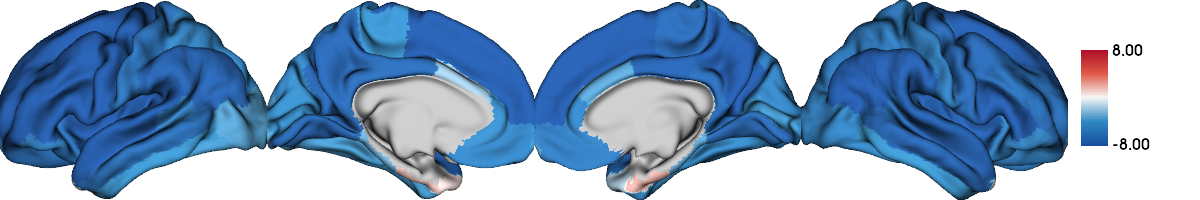

In [59]:
# plot t values in TLE
# label_text = ['TLE', 'IGE']

t_ctx_surf = parcel_to_surface(female_metrics['t_ctx'][0], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=True, color_range=(-8, 8))

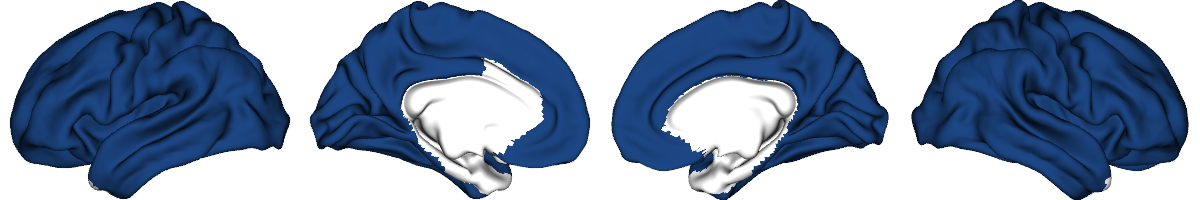

In [62]:
# plot p-sig areas
p_ctx_surf = parcel_to_surface(female_metrics['q_ctx'][0], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [63]:
q_ctx_tle = pd.Series(female_metrics['q_ctx'][0], index=ctx_tle.columns, name='pFDR')
q_ctx_tle[q_ctx_tle < 0.05].index

Index(['L_bankssts', 'L_caudalmiddlefrontal', 'L_cuneus', 'L_fusiform',
       'L_inferiorparietal', 'L_inferiortemporal', 'L_isthmuscingulate',
       'L_lateraloccipital', 'L_lateralorbitofrontal', 'L_lingual',
       'L_medialorbitofrontal', 'L_middletemporal', 'L_parahippocampal',
       'L_paracentral', 'L_parsopercularis', 'L_parsorbitalis',
       'L_parstriangularis', 'L_pericalcarine', 'L_postcentral',
       'L_posteriorcingulate', 'L_precentral', 'L_precuneus',
       'L_rostralanteriorcingulate', 'L_rostralmiddlefrontal',
       'L_superiorfrontal', 'L_superiorparietal', 'L_superiortemporal',
       'L_supramarginal', 'L_frontalpole', 'L_transversetemporal', 'L_insula',
       'R_bankssts', 'R_caudalanteriorcingulate', 'R_caudalmiddlefrontal',
       'R_cuneus', 'R_fusiform', 'R_inferiorparietal', 'R_inferiortemporal',
       'R_isthmuscingulate', 'R_lateraloccipital', 'R_lateralorbitofrontal',
       'R_lingual', 'R_medialorbitofrontal', 'R_middletemporal',
       'R_parah

In [64]:
len(q_ctx_tle[q_ctx_tle < 0.05])

63

In [65]:
# get the t values range for TLE in females
female_metrics['t_ctx'][0].min(), female_metrics['t_ctx'][0].max()

(-11.832518524303184, 1.8381397466740026)

In [66]:
# get the strongest effects (t values) for p significant regions for TLE in males
t_ctx_tle = pd.Series(female_metrics['t_ctx'][0], index=ctx_tle.columns, name="t")

tle_ctx = pd.DataFrame({
    "t": t_ctx_tle,
    "q-value": q_ctx_tle
})

tle_sig_ctx = tle_ctx[tle_ctx["q-value"] < 0.05].sort_values(by="t", ascending=True)
tle_sig_ctx.head(20)

,t,q-value
L_parsopercularis,-11.832519,3.852117e-27
L_superiorfrontal,-10.408511,8.996420e-22
L_caudalmiddlefrontal,-10.050998,1.341366e-20
R_parsopercularis,-9.010216,5.559862e-17
R_parstriangularis,-8.975802,5.847008e-17
R_superiorfrontal,-8.693261,4.470892e-16
R_precuneus,-8.220112,1.393922e-14
R_inferiorparietal,-8.147912,2.082730e-14
L_insula,-8.111714,2.417707e-14
L_rostralmiddlefrontal,-8.096906,2.426366e-14


IGE

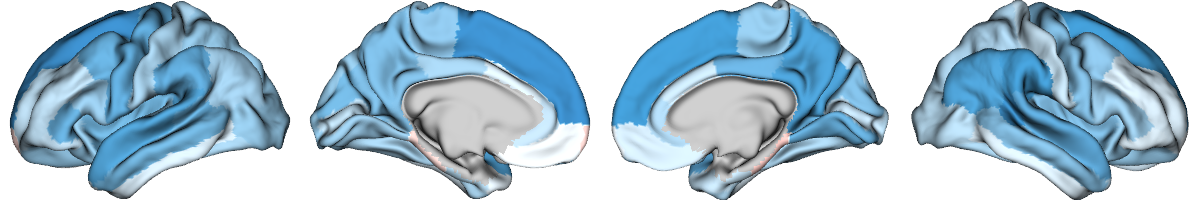

In [67]:
# plot t values in IGE
# label_text = ['TLE', 'IGE']

t_ctx_surf = parcel_to_surface(female_metrics['t_ctx'][1], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-8, 8))

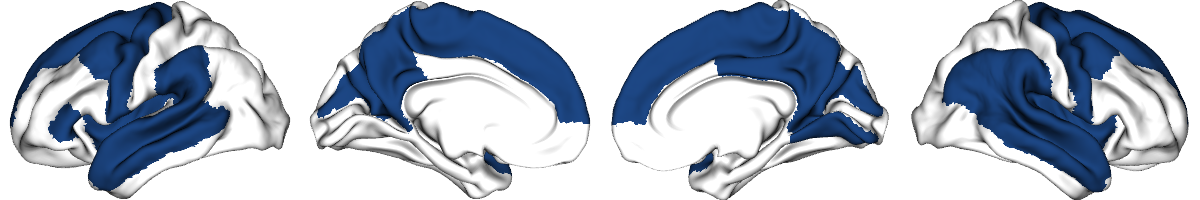

In [70]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(female_metrics['q_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [71]:
## Check which areas are significant
q_ctx_ige = pd.Series(female_metrics['q_ctx'][1], index=ctx_ige.columns, name='pFDR')
q_ctx_ige[q_ctx_ige < 0.05].index

Index(['L_bankssts', 'L_caudalmiddlefrontal', 'L_cuneus', 'L_isthmuscingulate',
       'L_middletemporal', 'L_paracentral', 'L_parstriangularis',
       'L_precentral', 'L_precuneus', 'L_superiorfrontal',
       'L_superiortemporal', 'L_supramarginal', 'L_insula', 'R_bankssts',
       'R_caudalmiddlefrontal', 'R_cuneus', 'R_inferiorparietal',
       'R_isthmuscingulate', 'R_lingual', 'R_middletemporal', 'R_paracentral',
       'R_posteriorcingulate', 'R_precentral', 'R_precuneus',
       'R_superiorfrontal', 'R_superiortemporal', 'R_supramarginal',
       'R_transversetemporal', 'R_insula'],
      dtype='object')

In [72]:
len(q_ctx_ige[q_ctx_ige < 0.05])

29

In [73]:
female_metrics['t_ctx'][1].min(), female_metrics['t_ctx'][1].max()

(-4.792029507387456, 1.4886652471477808)

In [74]:
t_ctx_ige = pd.Series(female_metrics['t_ctx'][1], index=ctx_ige.columns, name='pFDR')

ige_ctx = pd.DataFrame({
    "t": t_ctx_ige,
    "q-value": q_ctx_ige
})

ige_sig_ctx = ige_ctx[ige_ctx["q-value"] < 0.05].sort_values(by="t", ascending=True)
ige_sig_ctx.head(10)

,t,q-value
L_superiorfrontal,-4.792030,0.000347
R_bankssts,-4.592016,0.000393
R_superiorfrontal,-3.967045,0.002578
R_supramarginal,-3.922284,0.002578
R_isthmuscingulate,-3.778430,0.002753
R_precuneus,-3.756113,0.002753
R_inferiorparietal,-3.748250,0.002753
L_superiortemporal,-3.672916,0.003139
R_superiortemporal,-3.408143,0.006873
L_precentral,-3.349996,0.006915


Subcortical volumes in TLE

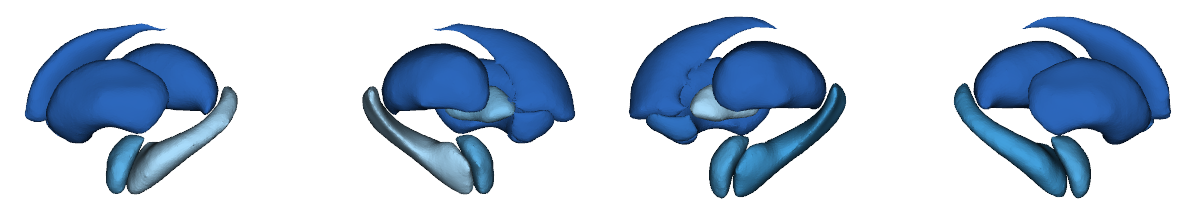

In [75]:
# plot t values in TLE
# label_text = ['TLE', 'IGE']

plot_subcortical(female_metrics['t_sv'][0], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-8, 8))

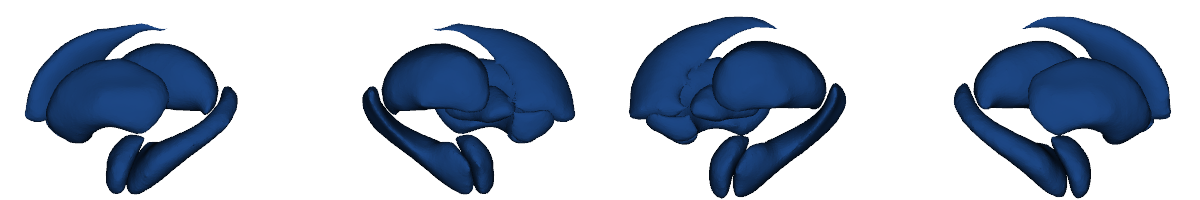

In [76]:
# plot p-sig areas

sig_mask = np.where(female_metrics['q_sv'][0] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [77]:
q_sv_tle = pd.Series(female_metrics['q_sv'][0], index=sv_tle.columns, name='pFDR')
q_sv_tle[q_sv_tle < 0.05].index

Index(['Laccumb', 'Lamyg', 'Lcaud', 'Lhippo', 'Lpal', 'Lput', 'Lthal',
       'Raccumb', 'Ramyg', 'Rcaud', 'Rhippo', 'Rpal', 'Rput', 'Rthal'],
      dtype='object')

In [78]:
female_metrics['t_sv'][0].min(), female_metrics['t_sv'][0].max()

(-9.039286400396003, -2.0725382638287178)

In [79]:
t_sv_tle = pd.Series(female_metrics['t_sv'][0], index=sv_tle.columns, name="t")

tle_sv = pd.DataFrame({
    "t": t_sv_tle,
    "q-value": q_sv_tle
})

tle_sig_sv = tle_sv[tle_sv["q-value"] < 0.05].sort_values(by="t", ascending=True)
tle_sig_sv.head()

,t,q-value
Lput,-9.039286,3.398916e-17
Rput,-8.961022,3.398916e-17
Rthal,-8.898034,3.728102e-17
Lthal,-8.778732,7.129664e-17
Lcaud,-8.422741,8.415320e-16


IGE

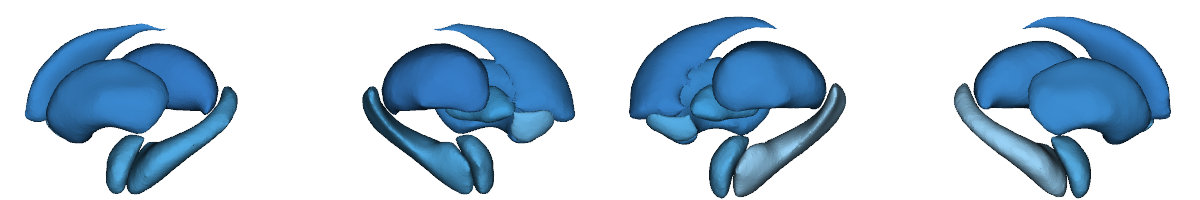

In [80]:
# label_text = ['TLE', 'IGE']

plot_subcortical(female_metrics['t_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-8, 8))

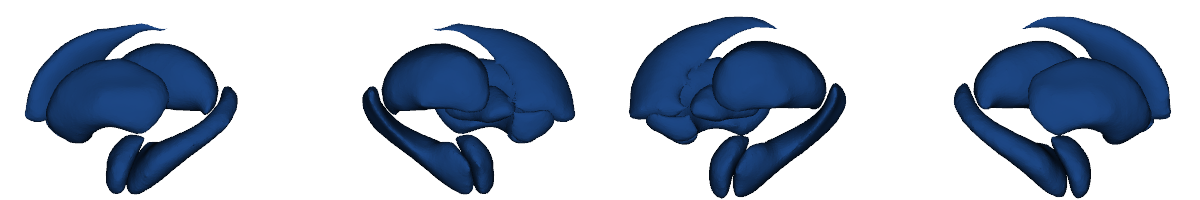

In [81]:
# plot p-sig areas

sig_mask = np.where(female_metrics['q_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [82]:
q_sv_ige = pd.Series(female_metrics['q_sv'][1], index=sv_ige.columns, name='pFDR')
q_sv_ige[q_sv_ige < 0.05].index

Index(['Laccumb', 'Lamyg', 'Lcaud', 'Lhippo', 'Lpal', 'Lput', 'Lthal',
       'Raccumb', 'Ramyg', 'Rcaud', 'Rhippo', 'Rpal', 'Rput', 'Rthal'],
      dtype='object')

In [83]:
female_metrics['t_sv'][1].min(), female_metrics['t_sv'][1].max()

(-6.497453553258952, -2.4331321294455064)

In [84]:
t_sv_ige = pd.Series(female_metrics['t_sv'][1], index=sv_ige.columns, name="t")

ige_sv = pd.DataFrame({
    "t": t_sv_ige,
    "q-value": q_sv_ige
})

ige_sig_sv = ige_sv[ige_sv["q-value"] < 0.05].sort_values(by="t", ascending=True)
ige_sig_sv.head()

,t,q-value
Lthal,-6.497454,3.354737e-08
Rcaud,-6.170301,7.962731e-08
Lput,-5.931122,1.331698e-07
Lcaud,-5.911343,1.331698e-07
Rthal,-5.777094,1.973223e-07


## Age, and age-by sex interaction effects

In [85]:
# glm comparison
biomarker_datasets = {
    'ctx': {'tle': ctx_tle, 'ige': ctx_ige},
    'sv': {'tle': sv_tle, 'ige': sv_ige}
}

comparison_types = ['age_sex_interaction']

results = {}
for epi in ['tle', 'ige']:
    results[epi] = {}
    for biomarker in ['ctx', 'sv']:
        results[epi][biomarker] = {}

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        glm = general_linear_model(demo, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        for comparison_type in comparison_types:
            results[epi][biomarker][comparison_type] = glm.clinical_correlate(
                df_name=df_name, comparison_type=comparison_type, durill="durill",
                ao="ao", age="Age", sex="Sex", icv="ICV")

2026-09-02 15:15:46,581 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-02 15:15:46,623 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-02 15:15:46,643 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-02 15:15:46,672 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables

In [86]:
# Reorganize results

epi_types = ['tle', 'ige']
biomarkers = ['ctx', 'sv']

comparison_types = ['age_sex_interaction']

metric_map = {
    't': 't_values', 'q': 'q_values',
    'beta': 'beta', 'ci_lower': 'ci_lower', 'ci_upper': 'ci_upper'
}

result_dicts = {}

for epi in epi_types:
    for biomarker in biomarkers:
        for metric_name, result_key in metric_map.items():

            values = np.vstack([np.asarray(results[epi][biomarker][comp][result_key]).flatten()
                for comp in comparison_types
            ])

            result_dicts[f'{metric_name}_{epi}_{biomarker}'] = values

In [ ]:
## Save

metrics_to_save = ['t', 'q', 'beta', 'ci_lower', 'ci_upper']
epi_to_save = ['tle', 'ige']
biomarkers = ['ctx', 'sv']
biomarker_index_map = {'ctx': ctx_tle.columns, 'sv': sv_tle.columns}

output_base = os.path.join(results_dir, '...')
os.makedirs(output_base, exist_ok=True)

for epi in epi_to_save:

    epi_dir = os.path.join(output_base, epi.upper())
    os.makedirs(epi_dir, exist_ok=True)

    for biomarker in biomarkers:
        index_cols = biomarker_index_map[biomarker]

        for metric in metrics_to_save:
            key = f"{metric}_{epi}_{biomarker}"

            if key not in result_dicts:
                continue

            values_all = result_dicts[key]
            values = values_all[0, :]

            df = pd.DataFrame(values, index=index_cols, columns=[f'{metric}_value'])
            df['analysis'] = 'age × sex interaction'
            df['predictor'] = 'age'
            df['interaction'] = 'sex'
            df['diagnosis'] = epi.upper()
            df['metric'] = metric
            df['biomarker'] = biomarker

            out_name = f'{metric}_{biomarker}.csv'
            df.to_csv(os.path.join(epi_dir, out_name), index=True)

### TLE results visualization

Sex age interaction effects in cortical thickness

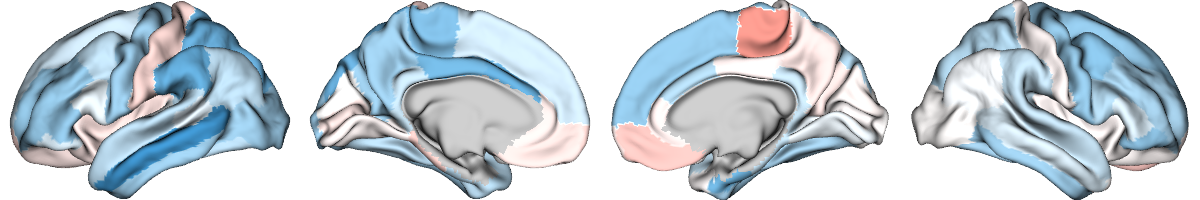

In [93]:
# plot t values
# label_text = ['sex * age']

t_ctx_surf = parcel_to_surface(result_dicts['t_tle_ctx'], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-5, 5))

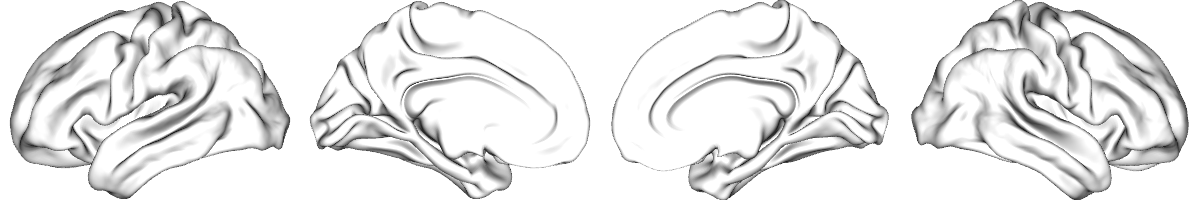

In [94]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_ctx'], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [97]:
q_ctx_tle = pd.Series(result_dicts['q_tle_ctx'][0], index=ctx_tle.columns, name='pFDR')
q_ctx_tle[q_ctx_tle < 0.05].index

Index([], dtype='object')

In [98]:
len(q_ctx_tle[q_ctx_tle < 0.05])

0

In [99]:
result_dicts['t_tle_ctx'].min(), result_dicts['t_tle_ctx'].max()

(-2.6661419480409347, 1.7582167297437914)

subcortical volume

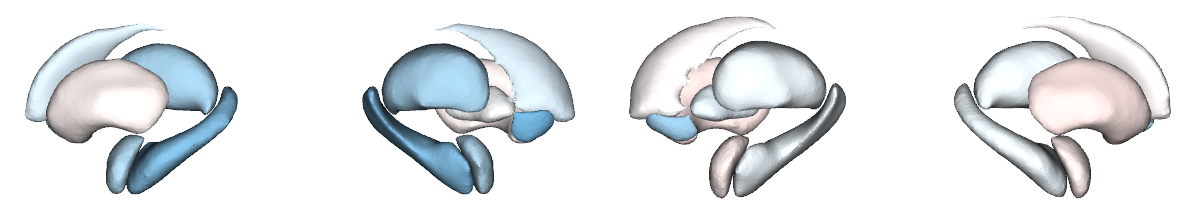

In [102]:
# plot cohen values
# label_text = ['sex * age']

plot_subcortical(result_dicts['t_tle_sv'][0], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-5, 5))


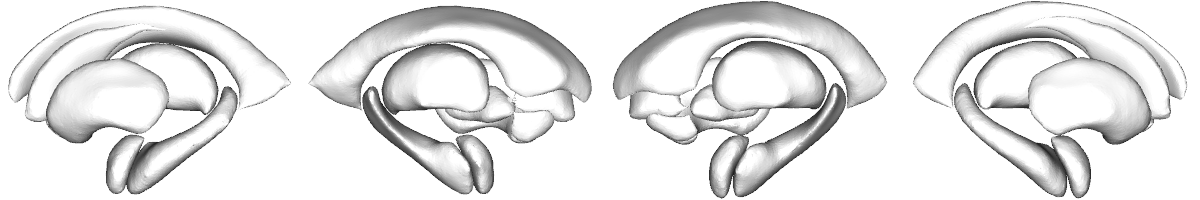

In [103]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_tle_sv'][0] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [104]:
q_sv_tle = pd.Series(result_dicts['q_tle_sv'][0], index=sv_tle.columns, name='pFDR')
q_sv_tle[q_sv_tle < 0.05].index

Index([], dtype='object')

In [105]:
len(q_sv_tle[q_sv_tle < 0.05])

0

In [ ]:
# get the t values range for sex in epilepsy
result_dicts['t_tle_sv'][0].min(), result_dicts['t_tle_sv'][0].max()

(-1.8466938277004734, 0.3957708141682704)

### Visualization in IGE

Sex age interaction effects in cortical thickness

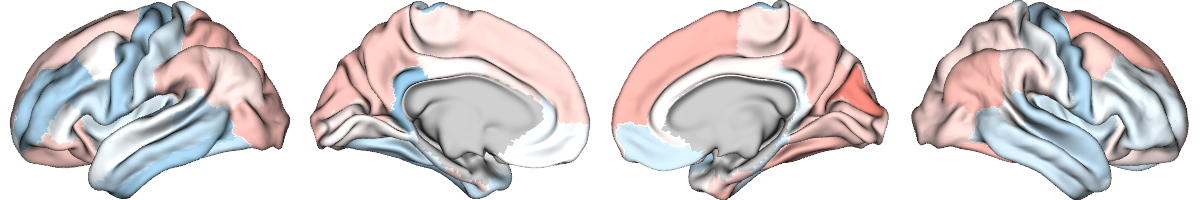

In [108]:
# plot t values
# label_text = ['sex * age']

t_ctx_surf = parcel_to_surface(result_dicts['t_ige_ctx'], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-5, 5))

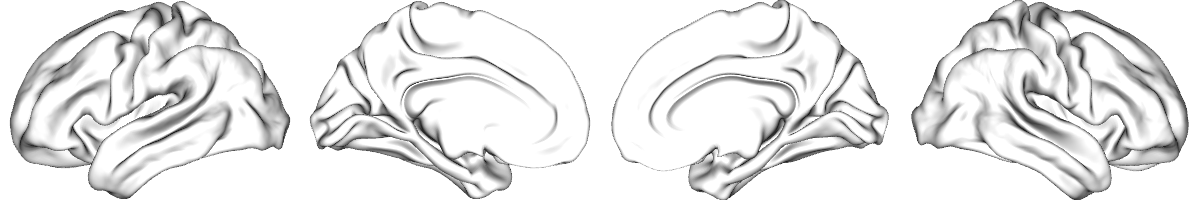

In [109]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_ige_ctx'], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [111]:
q_ctx_ige = pd.Series(result_dicts['q_ige_ctx'][0], index=ctx_ige.columns, name='pFDR')
q_ctx_ige[q_ctx_ige < 0.05].index

Index([], dtype='object')

In [112]:
len(q_ctx_ige[q_ctx_ige < 0.05])

0

In [113]:
result_dicts['t_ige_ctx'].min(), result_dicts['t_ige_ctx'].max()

(-1.382605771457972, 2.020906024044797)

Sex age interaction in subcortical volume

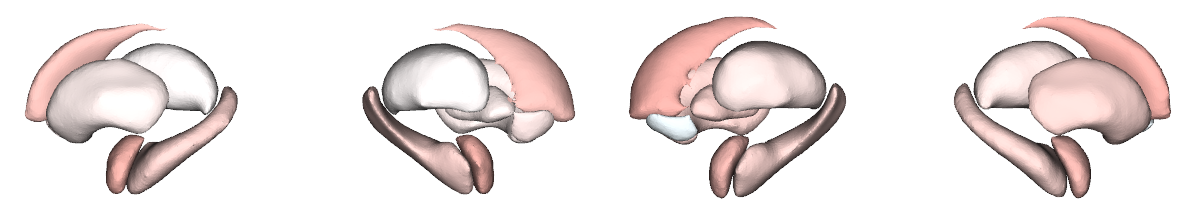

In [114]:
plot_subcortical(result_dicts['t_ige_sv'][0], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-5, 5))

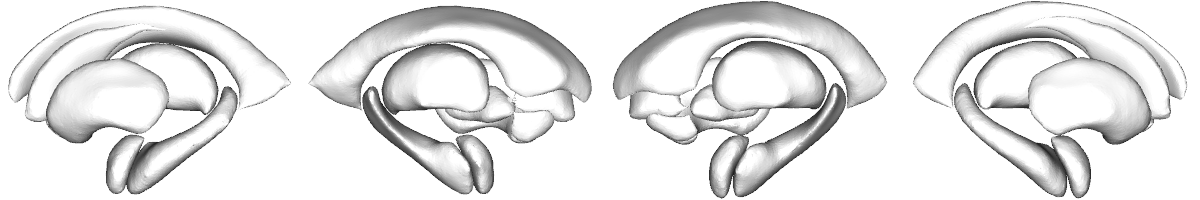

In [116]:
# plot p-sig areas
sig_mask = np.where(result_dicts['q_ige_sv'][0] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [117]:
q_sv_ige = pd.Series(result_dicts['q_ige_sv'][0], index=sv_ige.columns, name='pFDR')
q_sv_ige[q_sv_ige < 0.05].index

Index([], dtype='object')

In [118]:
len(q_sv_ige[q_sv_ige < 0.05])

0

In [119]:
result_dicts['t_ige_sv'][0].min(), result_dicts['t_ige_sv'][0].max()

(-0.28834446322073864, 1.2999362101176735)